In [1]:
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import warnings

warnings.filterwarnings(
    "ignore",
    message=".*`shuffle=True` was passed, but will be ignored.*",
    category=UserWarning
)

In [2]:
import tensorflow as tf
from tensorflow.keras import models , layers , callbacks , regularizers
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNELS = 3

dataset = tf.keras.utils.image_dataset_from_directory(
    directory = './dataset',
    image_size = (IMAGE_SIZE , IMAGE_SIZE),
    batch_size = BATCH_SIZE,
    shuffle = True,
    seed=42
)


Found 2152 files belonging to 3 classes.


In [4]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [5]:
for image_batch, label_batch in dataset.take(1):
    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)
    print("Label :", label_batch.numpy())

Image batch shape: (32, 256, 256, 3)
Label batch shape: (32,)
Label : [1 2 1 1 2 0 0 1 1 1 1 0 0 1 1 0 0 2 0 0 1 0 0 0 1 0 0 1 0 2 2 0]


[1 1 0 1 1 1 1 0 1 0 0 1 1 1 0 1 1 1 0 1 2 2 1 1 1 0 1 0 1 0 1 0]


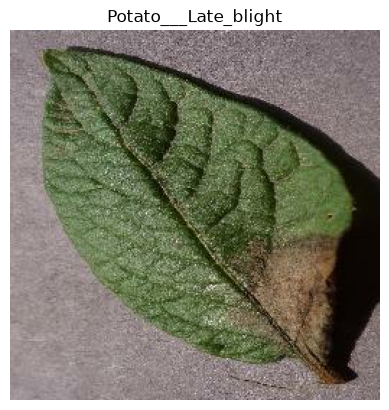

In [6]:
for image_batch, label_batch in dataset.take(1):

  plt.imshow(image_batch[0].numpy().astype("uint8"))
  plt.title(class_names[label_batch[0]])
  print(label_batch.numpy())
  plt.axis("off")

In [7]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=1000):
    ds_size = len(ds) # Total number of batches

    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=42)

    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)

    return train_ds, val_ds, test_ds

In [8]:
# Train Test Validation split
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [9]:
# Automatically tune the number of batches preloaded in memory
AUTOTUNE = tf.data.AUTOTUNE

# 1. Training Dataset: cache -> shuffle -> prefetch
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

# 2. Validation Dataset: cache -> prefetch
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# 3. Test Dataset: cache -> prefetch
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [10]:
# Sequential pipeline to format input images before feeding them to the CNN
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE), # Resizes input images to 256x256 dimensions
    layers.Rescaling(1.0 / 255.0)            # Normalizes pixel values from [0, 255] to [0, 1]
], name="preprocessing_pipeline")

In [37]:
# Define the Augmentation Sequential Model
data_augmentation = tf.keras.Sequential([
    # 1. Random Horizontal & Vertical Flip
    layers.RandomFlip("horizontal_and_vertical"),
    
    # 2. Random Rotation by up to +/- 20% (+/- 72 degrees)
    layers.RandomRotation(0.2),
    
    # 3. Random Zoom in/out by up to +/- 20%
    layers.RandomZoom(height_factor=(-0.2, 0.2), width_factor=(-0.2, 0.2)),

], name="data_augmentation")

In [38]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNELS = 3

input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)

model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),
    resize_and_rescale,
    
    # Standard geometric augmentation
    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 4 (Capped at 128 filters to reduce complexity)
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 5 (NEW) - Reduces spatial size to 2x2 before flattening
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # The Head
    layers.Flatten(), 
    
    # Dense layer with L2 Regularization to mathematically block memorization
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.Dropout(0.2),
    layers.Dense(3, activation='softmax')
], name='CNN_Anti_Overfit_Detector')

model.summary()

Model: "CNN_Anti_Overfit_Detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocessing_pipeline          │ (None, 256, 256, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 790,083 (3.01 MB)

 Trainable params: 790,083 (3.01 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# 1. Compile with Gradient Clipping (prevents sudden loss spikes like Epoch 7)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# 2. Custom Callback to track and announce the exact best epoch
class BestEpochTracker(callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.best_val_acc = 0.0
        self.best_val_loss = float('inf')
        self.best_epoch = 0

    def on_epoch_end(self, epoch, logs=None):
        val_acc = logs.get('val_accuracy')
        val_loss = logs.get('val_loss')
        if val_loss < self.best_val_loss:
            self.best_val_loss = val_loss
            self.best_val_acc = val_acc
            self.best_epoch = epoch + 1
            print(f"\n--> [New Best] Epoch {self.best_epoch}: val_loss = {val_loss:.4f}, val_accuracy = {val_acc*100:.2f}%")

    def on_train_end(self, logs=None):
        print(f"\n==========================================")
        print(f"Training Complete! Best Model at Epoch {self.best_epoch}")
        print(f"Best Val Loss: {self.best_val_loss:.4f} | Best Val Acc: {self.best_val_acc*100:.2f}%")
        print(f"==========================================")

# 3. Combine Custom Tracker with Standard Production Callbacks
training_callbacks = [
    BestEpochTracker(),
    
    # Smoothly halves the learning rate when validation loss stalls for 3 epochs
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    
    # Saves ONLY the single best model weights to disk
    callbacks.ModelCheckpoint(
        filepath='best_potato_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    ),
    
    # Stops training if no improvement after 7 epochs and automatically restores the best weights
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

In [40]:
# 4. Run Training
EPOCHS = 30 

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=training_callbacks
)

Epoch 1/30
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.4839 - loss: 1.3143
--> [New Best] Epoch 1: val_loss = 0.8281, val_accuracy = 70.31%
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.4859 - loss: 1.3042 - val_accuracy: 0.7031 - val_loss: 0.8281 - learning_rate: 0.0010
Epoch 2/30
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7943 - loss: 0.6430
--> [New Best] Epoch 2: val_loss = 0.7628, val_accuracy = 80.21%
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.7958 - loss: 0.6389 - val_accuracy: 0.8021 - val_loss: 0.7628 - learning_rate: 0.0010
Epoch 3/30
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8084 - loss: 0.5671
--> [New Best] Epoch 3: val_loss = 0.6009, val_accuracy = 82.29%
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.8093 - loss: 0.5654 - val_accuracy: 0.8229 - val_loss: 0.6009 - learning_rate: 0.0010
Epoch 4/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8568 - loss: 0.4636
--> [New Best] Epoch 4: val_loss = 0.4238, va

## Model Evaluation

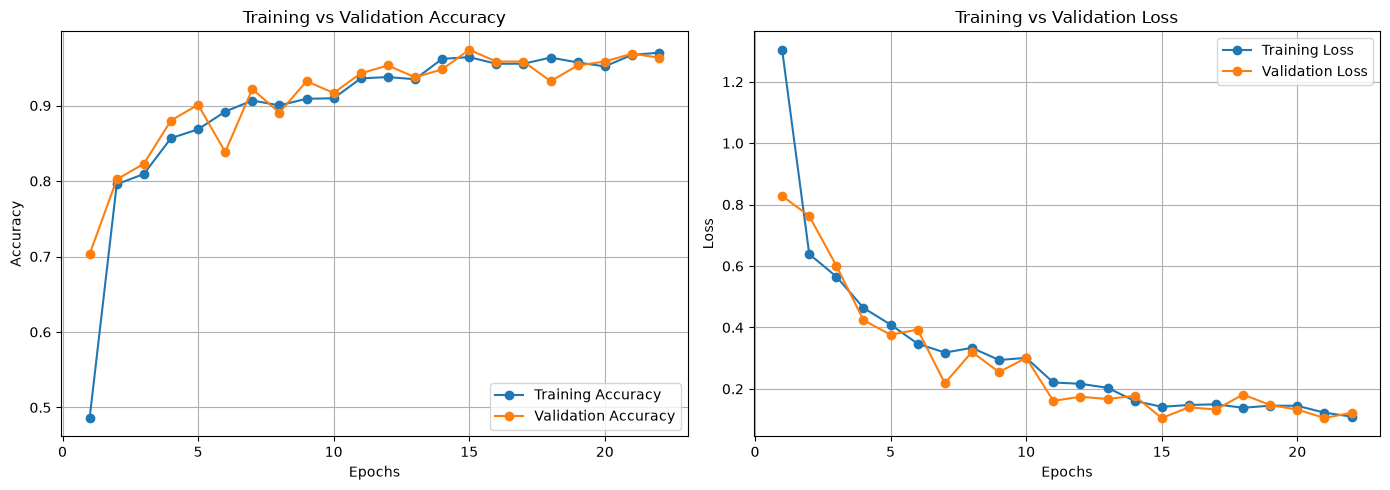

In [43]:
# Extract metrics from history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9453 - loss: 0.1874

Final Test Loss: 0.1874
Final Test Accuracy: 94.53%

--- Classification Report ---
                       precision    recall  f1-score   support

Potato___Early_blight       0.91      1.00      0.95       123
 Potato___Late_blight       1.00      0.88      0.94       119
     Potato___healthy       0.88      1.00      0.93        14

             accuracy                           0.95       256
            macro avg       0.93      0.96      0.94       256
         weighted avg       0.95      0.95      0.94       256



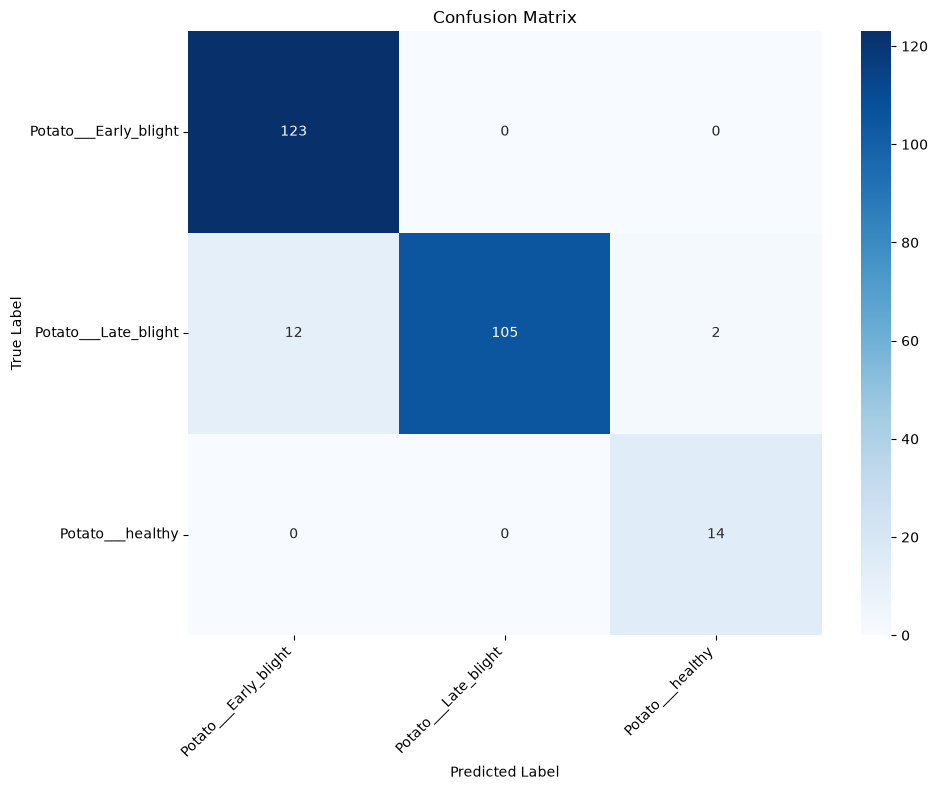

In [44]:
# 1. Evaluate performance metrics on isolated test_ds
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nFinal Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%\n")

# 2. Extract true labels and predicted labels across all test batches
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 3. Print Classification Report (Precision, Recall, F1-Score per class)
print("--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 4. Plot Heatmap Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

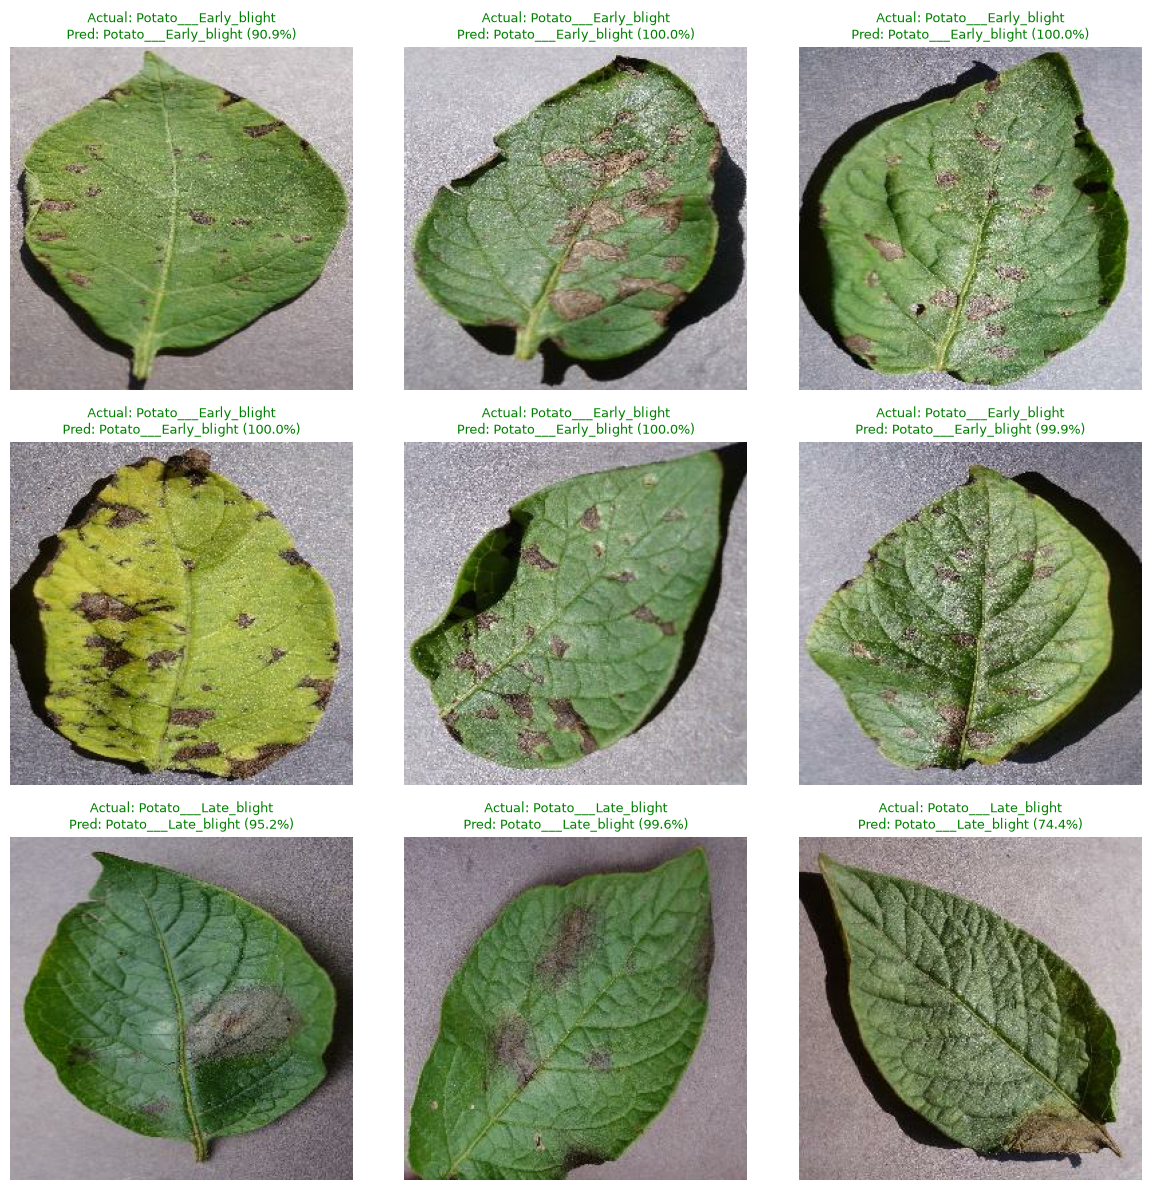

In [45]:
plt.figure(figsize=(12, 12))

for images, labels in test_ds.take(2):
    predictions = model.predict(images, verbose=0)
    
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        
        # Display image
        plt.imshow(images[i].numpy().astype("uint8"))
        
        actual_class = class_names[labels[i]]
        predicted_class = class_names[np.argmax(predictions[i])]
        confidence = np.max(predictions[i]) * 100
        
        # Highlight incorrect predictions in red
        color = 'green' if actual_class == predicted_class else 'red'
        
        plt.title(f"Actual: {actual_class}\nPred: {predicted_class} ({confidence:.1f}%)", 
                  color=color, fontsize=9)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
model_version = 1
model.export(f"../models/model_{model_version}")

INFO:tensorflow:Assets written to: ../models/model_1/assets


INFO:tensorflow:Assets written to: ../models/model_1/assets


Saved artifact at '../models/model_1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor_24')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140275872197200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140275872198352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140275854162832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273060742352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273060742544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273061079056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273061083280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273061076944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273061077136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273061077328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1402730613

## Experimentations

In [47]:
# Define the Augmentation Sequential Model
data_augmentation1 = tf.keras.Sequential([
    # 1. Random Horizontal & Vertical Flip
    layers.RandomFlip("horizontal_and_vertical"),
    
    # 2. Random Rotation by up to +/- 20% (+/- 72 degrees)
    layers.RandomRotation(0.2),
    
], name="data_augmentation_1")

In [48]:
IMAGE_SIZE = 256
CHANNELS = 3
input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = len(class_names)  # 3 for your Potato dataset

model1 = models.Sequential([
    layers.Input(shape=input_shape),
    resize_and_rescale,
    data_augmentation1,

    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 5
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 6
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification Head
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
], name="CNN_6Block_Potato_Detector")

model1.summary()

Model: "CNN_6Block_Potato_Detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocessing_pipeline          │ (None, 256, 256, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation_1             │ (None, 256, 256, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
# 1. Compile with Gradient Clipping (prevents sudden loss spikes like Epoch 7)
model1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# 2. Custom Callback to track and announce the exact best epoch
class BestEpochTracker1(callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.best_val_acc = 0.0
        self.best_val_loss = float('inf')
        self.best_epoch = 0

    def on_epoch_end(self, epoch, logs=None):
        val_acc = logs.get('val_accuracy')
        val_loss = logs.get('val_loss')
        if val_loss < self.best_val_loss:
            self.best_val_loss = val_loss
            self.best_val_acc = val_acc
            self.best_epoch = epoch + 1
            print(f"\n--> [New Best] Epoch {self.best_epoch}: val_loss = {val_loss:.4f}, val_accuracy = {val_acc*100:.2f}%")

    def on_train_end(self, logs=None):
        print(f"\n==========================================")
        print(f"Training Complete! Best Model at Epoch {self.best_epoch}")
        print(f"Best Val Loss: {self.best_val_loss:.4f} | Best Val Acc: {self.best_val_acc*100:.2f}%")
        print(f"==========================================")

# 3. Combine Custom Tracker with Standard Production Callbacks
training_callbacks1 = [
    BestEpochTracker1(),
    
    # Smoothly halves the learning rate when validation loss stalls for 3 epochs
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    
    # Saves ONLY the single best model weights to disk
    callbacks.ModelCheckpoint(
        filepath='best_potato_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    ),
    
    # Stops training if no improvement after 7 epochs and automatically restores the best weights
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

In [50]:
# 4. Run Training
EPOCHS1 = 30 

history1 = model1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS1,
    callbacks=training_callbacks1
)

Epoch 1/30
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.4910 - loss: 0.9142
--> [New Best] Epoch 1: val_loss = 0.8436, val_accuracy = 47.92%
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.4912 - loss: 0.9151 - val_accuracy: 0.4792 - val_loss: 0.8436 - learning_rate: 0.0010
Epoch 2/30
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6178 - loss: 0.8185
--> [New Best] Epoch 2: val_loss = 0.6229, val_accuracy = 71.88%
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.6227 - loss: 0.8138 - val_accuracy: 0.7188 - val_loss: 0.6229 - learning_rate: 0.0010
Epoch 3/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7359 - loss: 0.6145
--> [New Best] Epoch 3: val_loss = 0.4779, val_accuracy = 79.17%
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.7359 - loss: 0.6145 - val_accuracy: 0.7917 - val_loss: 0.4779 - learning_rate: 0.0010
Epoch 4/30
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8074 - loss: 0.4842
--> [New Best] Epoch 4: val_loss = 0.3398, va

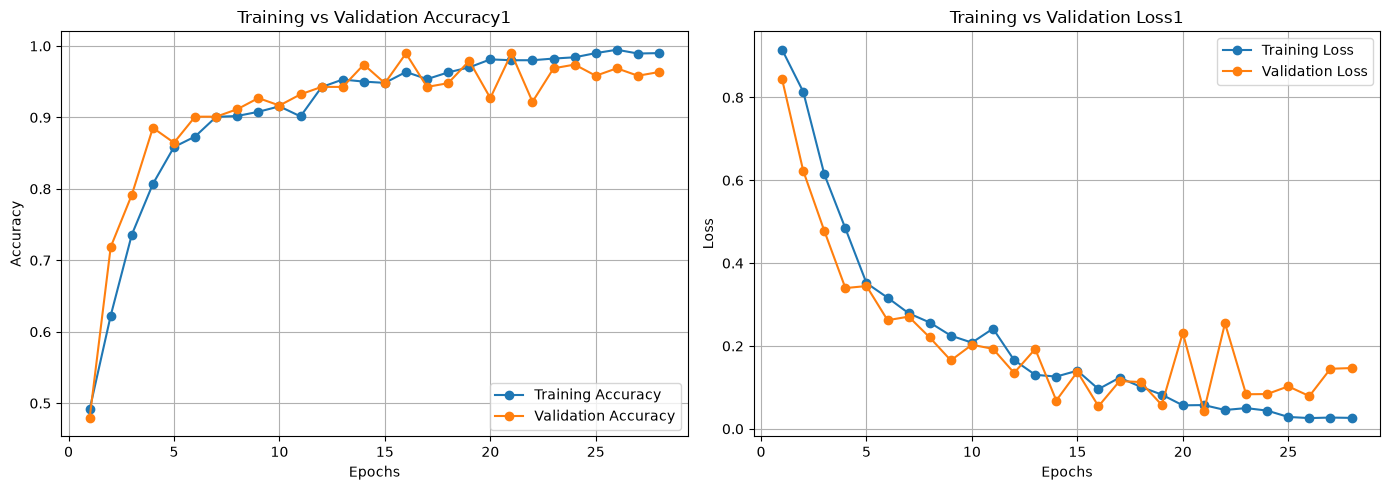

In [52]:
# Extract metrics from history
acc1 = history1.history['accuracy']
val_acc1 = history1.history['val_accuracy']
loss1 = history1.history['loss']
val_loss1 = history1.history['val_loss']

epochs_range1 = range(1, len(acc1) + 1)

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range1, acc1, label='Training Accuracy', marker='o')
plt.plot(epochs_range1, val_acc1, label='Validation Accuracy', marker='o')
plt.title('Training vs Validation Accuracy1')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range1, loss1, label='Training Loss', marker='o')
plt.plot(epochs_range1, val_loss1, label='Validation Loss', marker='o')
plt.title('Training vs Validation Loss1')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9922 - loss: 0.0256

Final Test Loss: 0.0256
Final Test Accuracy: 99.22%

--- Classification Report ---
                       precision    recall  f1-score   support

Potato___Early_blight       1.00      0.98      0.99       123
 Potato___Late_blight       0.98      1.00      0.99       119
     Potato___healthy       1.00      1.00      1.00        14

             accuracy                           0.99       256
            macro avg       0.99      0.99      0.99       256
         weighted avg       0.99      0.99      0.99       256



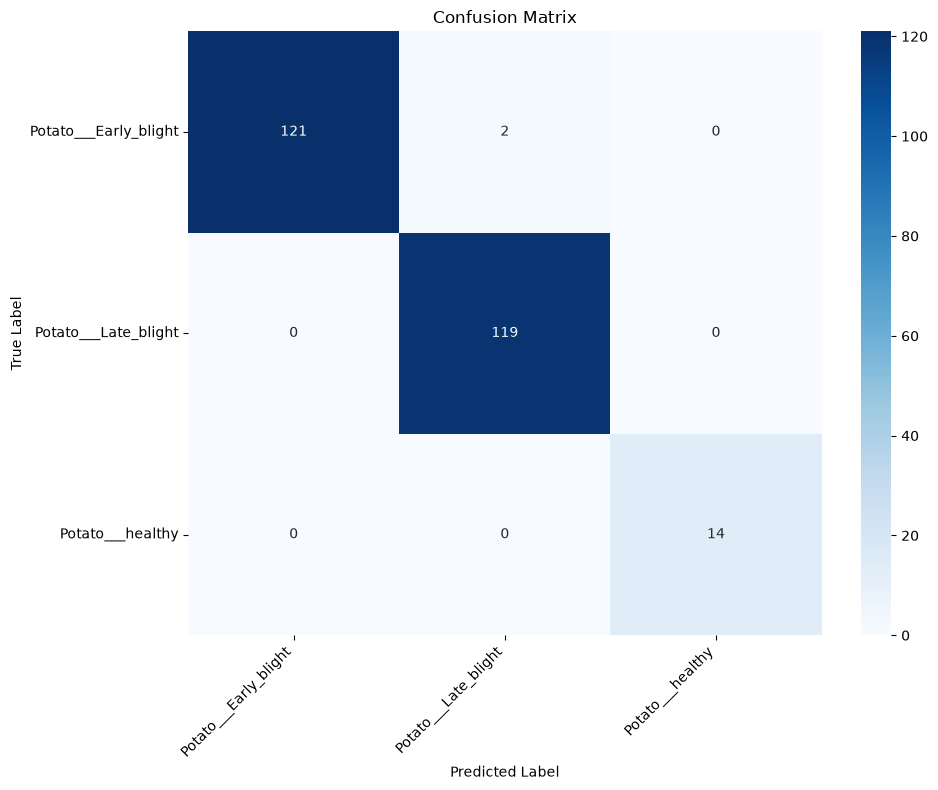

In [53]:
# 1. Evaluate performance metrics on isolated test_ds
test_loss1, test_acc1 = model1.evaluate(test_ds)
print(f"\nFinal Test Loss: {test_loss1:.4f}")
print(f"Final Test Accuracy: {test_acc1 * 100:.2f}%\n")

# 2. Extract true labels and predicted labels across all test batches
y_true1 = []
y_pred1 = []

for images, labels in test_ds:
    preds1 = model1.predict(images, verbose=0)
    y_true1.extend(labels.numpy())
    y_pred1.extend(np.argmax(preds1, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 3. Print Classification Report (Precision, Recall, F1-Score per class)
print("--- Classification Report ---")
print(classification_report(y_true1, y_pred1, target_names=class_names))

# 4. Plot Heatmap Confusion Matrix
cm = confusion_matrix(y_true1, y_pred1)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

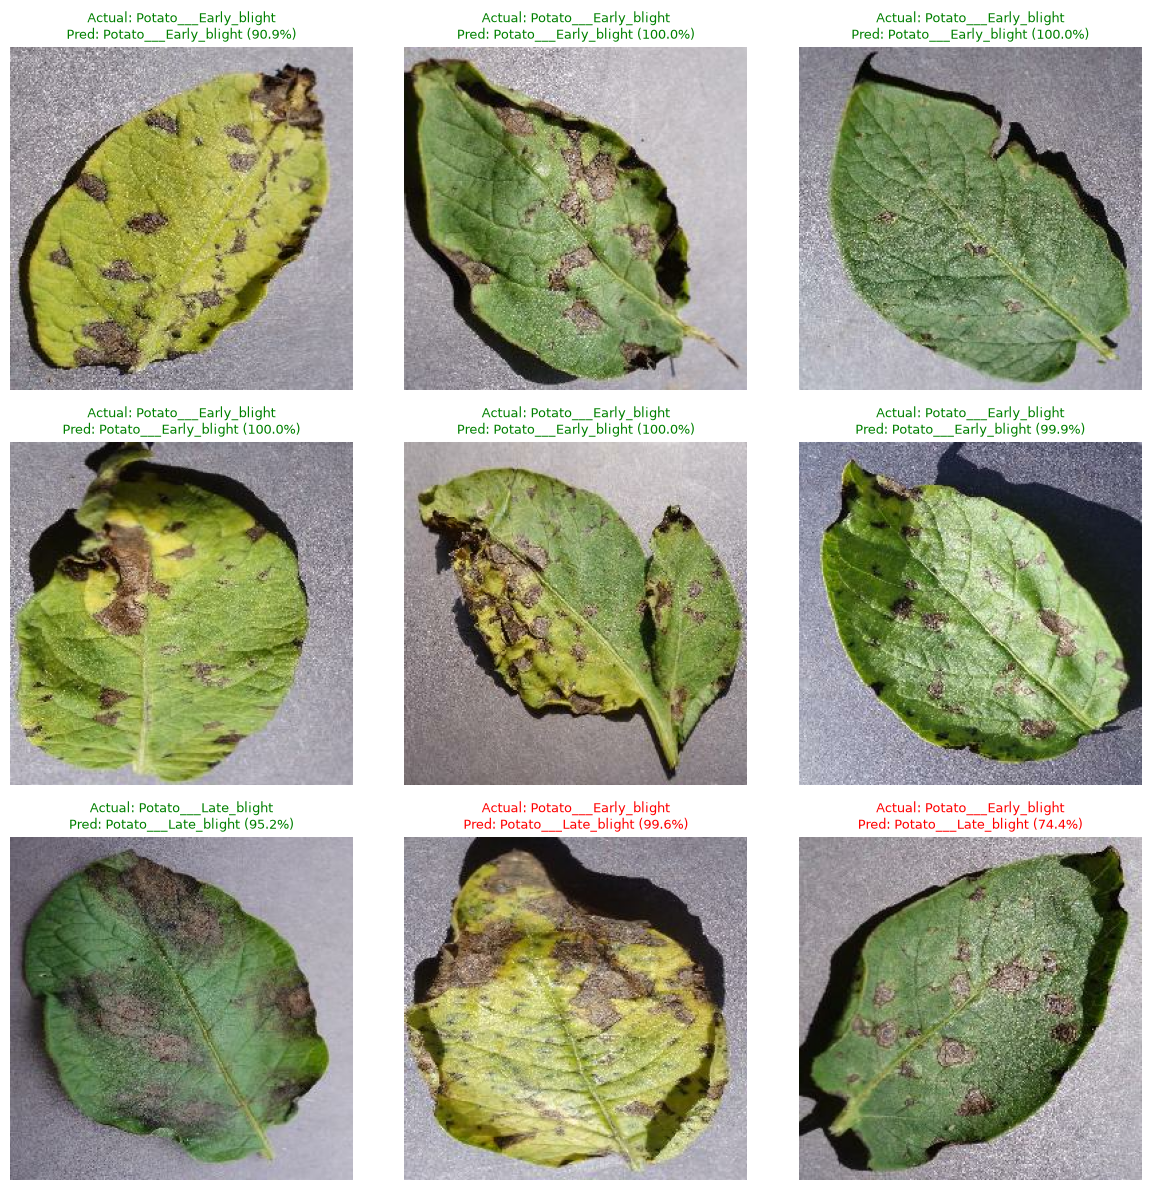

In [55]:
plt.figure(figsize=(12, 12))

for images, labels in test_ds.take(1):
    predictions1 = model1.predict(images, verbose=0)
    
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        
        # Display image
        plt.imshow(images[i].numpy().astype("uint8"))
        
        actual_class = class_names[labels[i]]
        predicted_class = class_names[np.argmax(predictions[i])]
        confidence = np.max(predictions[i]) * 100
        
        # Highlight incorrect predictions in red
        color = 'green' if actual_class == predicted_class else 'red'
        
        plt.title(f"Actual: {actual_class}\nPred: {predicted_class} ({confidence:.1f}%)", 
                  color=color, fontsize=9)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [66]:
model_version = 2
model1.export(f"../models/model_{model_version}")

INFO:tensorflow:Assets written to: ../models/model_2/assets


INFO:tensorflow:Assets written to: ../models/model_2/assets


Saved artifact at '../models/model_2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor_101')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140273061328848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273061328464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270682276880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270680316560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270680316752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270682269136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270682269328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270683797648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270682262992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270682273552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140270680

In [59]:
def predict_batch_tta(model, images):
    """Runs 6-view Test-Time Augmentation on a batch of images."""
    # View 1: Original image
    p1 = model1.predict(images, verbose=0)
    
    # View 2: Horizontal flip
    p2 = model1.predict(tf.image.flip_left_right(images), verbose=0)
    
    # View 3: Vertical flip
    p3 = model1.predict(tf.image.flip_up_down(images), verbose=0)
    
    # View 4: 90-degree rotation
    p4 = model1.predict(tf.image.rot90(images, k=1), verbose=0)
    
    # View 5: 180-degree rotation
    p5 = model1.predict(tf.image.rot90(images, k=2), verbose=0)
    
    # View 6: 270-degree rotation
    p6 = model1.predict(tf.image.rot90(images, k=3), verbose=0)
    
    # Average the softmax probabilities across all 6 views
    avg_probs = (p1 + p2 + p3 + p4 + p5 + p6) / 6.0
    return avg_probs

# Evaluate entire test_ds using TTA
y_true_tta = []
y_pred_tta = []
tta_confidences = []

for images, labels in test_ds:
    avg_probs = predict_batch_tta(model, images)
    
    y_true_tta.extend(labels.numpy())
    y_pred_tta.extend(np.argmax(avg_probs, axis=1))
    tta_confidences.extend(np.max(avg_probs, axis=1))

y_true_tta = np.array(y_true_tta)
y_pred_tta = np.array(y_pred_tta)

# Calculate new TTA accuracy
tta_acc = np.mean(y_true_tta == y_pred_tta) * 100
print(f"TTA Test Accuracy: {tta_acc:.2f}% ({np.sum(y_true_tta == y_pred_tta)}/{len(y_true_tta)} correct)\n")

print("--- TTA Classification Report ---")
print(classification_report(y_true_tta, y_pred_tta, target_names=class_names))

TTA Test Accuracy: 99.22% (254/256 correct)

--- TTA Classification Report ---
                       precision    recall  f1-score   support

Potato___Early_blight       1.00      0.98      0.99       123
 Potato___Late_blight       0.98      1.00      0.99       119
     Potato___healthy       1.00      1.00      1.00        14

             accuracy                           0.99       256
            macro avg       0.99      0.99      0.99       256
         weighted avg       0.99      0.99      0.99       256



## Testing the model

In [65]:
import json
import numpy as np
import tensorflow as tf

loaded_model = tf.keras.models.load_model("../models/model_2.keras")

def predict_leaf(image_path, threshold=0.80):
    img = tf.keras.utils.load_img(image_path, target_size=(256, 256))
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_array, axis=0)  # Rescaling is built into the model

    probs = loaded_model.predict(img_batch, verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    if confidence < threshold:
        return {
            "status": "uncertain",
            "prediction": class_names[pred_idx],
            "confidence": round(confidence * 100, 2),
            "message": "Low confidence — please retake a closer photo in clear lighting."
        }

    return {
        "status": "confident",
        "prediction": class_names[pred_idx],
        "confidence": round(confidence * 100, 2)
    }

In [67]:
import json

# Save the full Keras 3 model (architecture + weights + optimizer state)
model1.save(f"../models/model_{model_version}.keras")

# Save exact class index mapping
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Model and class mapping saved successfully!")

Model and class mapping saved successfully!


In [69]:
import json
import numpy as np
import tensorflow as tf

# 1. Load the saved .keras model and class names
loaded_model = tf.keras.models.load_model(f"../models/model_{model_version}.keras")

with open("class_names.json", "r") as f:
    class_names = json.load(f)

# 2. Single-image inference function with confidence threshold
def predict_potato_leaf(image_path, threshold=0.80):
    # Load and resize image to match model input (256x256)
    img = tf.keras.utils.load_img(image_path, target_size=(256, 256))
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_array, axis=0)  # Shape: (1, 256, 256, 3)

    # Note: Do NOT divide by 255.0 here because resize_and_rescale is inside the model
    probabilities = loaded_model.predict(img_batch, verbose=0)[0]
    
    pred_index = int(np.argmax(probabilities))
    confidence = float(probabilities[pred_index])
    predicted_class = class_names[pred_index]

    # Breakdown of all class probabilities
    all_scores = {
        name: f"{prob * 100:.2f}%" 
        for name, prob in zip(class_names, probabilities)
    }

    if confidence < threshold:
        return {
            "status": "uncertain",
            "predicted_class": predicted_class,
            "confidence": f"{confidence * 100:.2f}%",
            "all_probabilities": all_scores,
            "recommendation": "Confidence is below 80%. Capture a clearer, closer photo of the leaf."
        }

    return {
        "status": "confident",
        "predicted_class": predicted_class,
        "confidence": f"{confidence * 100:.2f}%",
        "all_probabilities": all_scores
    }



In [76]:
# Example usage:
result = predict_potato_leaf("./dataset/Potato___Early_blight/ad8c76f3-16b3-4d7f-a9e9-cbec8c398d34___RS_Early.B 6694.JPG")
print(result)

{'status': 'confident', 'predicted_class': 'Potato___Early_blight', 'confidence': '100.00%', 'all_probabilities': {'Potato___Early_blight': '100.00%', 'Potato___Late_blight': '0.00%', 'Potato___healthy': '0.00%'}}


In [71]:
loss, acc = loaded_model.evaluate(test_ds, verbose=0)
print(f"Reloaded Model -> Test Loss: {loss:.4f} | Test Accuracy: {acc * 100:.2f}%")

Reloaded Model -> Test Loss: 0.0256 | Test Accuracy: 99.22%
